---
title: "Momentum and Collisions — Level 2"
short_title: "02 Momentum & Collisions"
numbering:
  heading_2: true
  equation: true
---

# Momentum and Collisions

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 8 | Conserve momentum in 1D and 2D collisions with numbers |
| **2** | **Taylor, ch. 3 and 14** | **Work in the center-of-mass frame, find scattering angles, handle variable mass** |
| 3 | Goldstein, ch. 3 and 8 | Scattering cross sections and relativistic collisions |

The new skill at this level: changing frames to make a problem simple, and writing momentum balance for systems that gain or lose mass

Math for this topic: M2, coordinates, multiple integrals and the delta function.
:::

The Newton's laws notes derived $\dot{\mathbf{P}} = \mathbf{F}^{\text{ext}}$ for a system of particles. This notebook puts that result to work. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp, quad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
g = 9.81  # m/s^2

## Center of Mass of Extended Bodies

For a continuous body, the sum over particles becomes an integral:

$$
\mathbf{R} = \frac1M\int\mathbf{r}\,dm = \frac1M\int\mathbf{r}\,\rho(\mathbf{r})\,dV .
$$

Symmetry usually fixes all but one coordinate, and a well-chosen coordinate system (with its Jacobian) handles the rest. The half-disk in the math notes has its center of mass at $4R/(3\pi)$ from the flat edge. A solid hemisphere has it at $3R/8$, and a solid cone of height $h$ at $h/4$ above the base.

The center of mass matters because the total momentum of any system is $\mathbf{P} = M\dot{\mathbf{R}}$, and it changes only by external force:

$$
M\ddot{\mathbf{R}} = \mathbf{F}^{\text{ext}} .
$$ (eq-cm-motion)

## Rockets and Variable Mass

A rocket is the standard system whose mass changes. Apply momentum conservation over a short time $dt$. At time $t$ the rocket has mass $m$ and velocity $v$. During $dt$ it ejects mass $-dm > 0$ backward at speed $u$ **relative to the rocket**, so the exhaust moves at $v - u$.

Total momentum after, minus before, equals the external impulse:

$$
(m + dm)(v + dv) + (-dm)(v - u) - mv = F^{\text{ext}}dt .
$$

Dropping the second-order term $dm\,dv$ leaves the **rocket equation**:

$$
m\dot v = -\dot m\,u + F^{\text{ext}} .
$$ (eq-rocket)

The term $-\dot m\,u$ (positive, since $\dot m<0$) is the **thrust**. With no external force, separating variables gives

$$
v - v_0 = u\ln\frac{m_0}{m} .
$$ (eq-tsiolkovsky)

The velocity gain depends only on the exhaust speed and the **mass ratio**, not on how fast the fuel is burned. The logarithm is the reason rockets are mostly fuel: each extra $u$ of velocity multiplies the required mass ratio by $e \approx 2.7$.

:::{warning} Do not use $F = d(mv)/dt$ blindly
Writing $F = \frac{d}{dt}(mv) = m\dot v + \dot m v$ for a rocket gives the wrong answer, because it assumes the ejected mass leaves with zero velocity. The momentum balance above, done for the whole system including the exhaust, is always safe.
:::

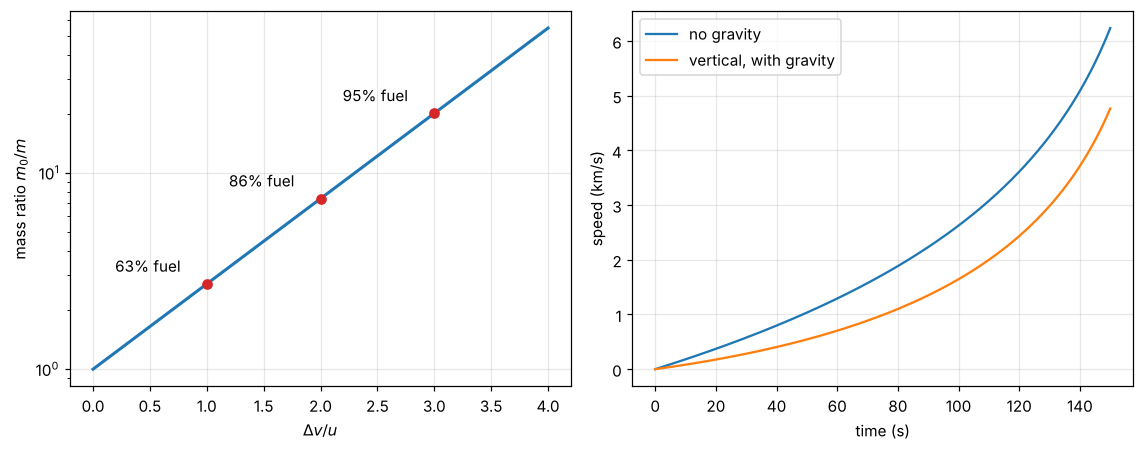

In [2]:
#| label: fig-rocket
#| caption: Left, the mass ratio needed for a velocity change Δv grows exponentially with Δv/u. Right, a vertical launch (u = 3 km/s, burn time 150 s, mass ratio 8) with and without gravity; gravity costs g·t_burn ≈ 1.5 km/s.
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
x = np.linspace(0, 4, 200)
axes[0].semilogy(x, np.exp(x), lw=2)
for mark in [1, 2, 3]:
    axes[0].plot(mark, np.exp(mark), "o", color="tab:red")
    axes[0].annotate(f"{100 * (1 - np.exp(-mark)):.0f}% fuel", (mark, np.exp(mark)),
                     textcoords="offset points", xytext=(-60, 8))
axes[0].set_xlabel(r"$\Delta v / u$"); axes[0].set_ylabel(r"mass ratio $m_0/m$")

u, tb, R = 3000.0, 150.0, 8.0
m0 = 1.0; k = m0 * (1 - 1 / R) / tb
t = np.linspace(0, tb, 300)
v_free = u * np.log(m0 / (m0 - k * t))
axes[1].plot(t, v_free / 1000, label="no gravity")
axes[1].plot(t, (v_free - g * t) / 1000, label="vertical, with gravity")
axes[1].set_xlabel("time (s)"); axes[1].set_ylabel("speed (km/s)"); axes[1].legend()
plt.tight_layout(); plt.show()

::::{prf:example} Reaching orbit
:label: ex-orbit-dv

Reaching low Earth orbit takes a total $\Delta v$ of roughly $9.4$ km/s once gravity and drag losses are included. With a high-performance hydrogen–oxygen engine ($u\approx4.4$ km/s), what fraction of a single-stage rocket's launch mass must be propellant?

:::{dropdown} Solution
From {eq}`eq-tsiolkovsky`, $m_0/m = e^{9.4/4.4}\approx e^{2.14}\approx8.5$. The final mass (structure, engines, tanks and payload together) is only about $12\%$ of the launch mass, so about $88\%$ must be propellant. Since tanks and engines are themselves heavy, almost nothing is left for payload. **Staging**, dropping empty tanks along the way, is how real rockets escape this squeeze.
:::
::::

### Exercises

1. A rocket in free space has $u = 3.0$ km/s. What fraction of its initial mass must be fuel for it to gain $6.0$ km/s?
2. Sand falls at a steady rate $\lambda$ (kg/s) onto a conveyor belt moving at constant speed $v$. What horizontal force keeps the belt moving? Compare the power supplied with the rate at which the sand gains kinetic energy.

:::{dropdown} Hints
1. The mass ratio is $e^{\Delta v/u}$.
2. Each second, mass $\lambda$ goes from zero horizontal velocity to $v$.
:::

:::{dropdown} Answers
1. $m_0/m = e^2\approx7.4$, so about $86\%$ fuel.
2. $F = \lambda v$, and the power is $Fv = \lambda v^2$. The sand gains kinetic energy at only $\tfrac12\lambda v^2$; the other half is dissipated as the sand skids before it catches up with the belt.
:::

## The Center-of-Mass Frame

For two bodies, the **center-of-mass (CM) frame** moves with velocity $\mathbf{V} = (m_1\mathbf{v}_1 + m_2\mathbf{v}_2)/(m_1 + m_2)$. In that frame the total momentum is zero, so the two momenta are always equal and opposite. Collisions are much simpler there.

Split the kinetic energy into the motion of the center of mass and the motion relative to it:

$$
T = \tfrac12 MV^2 + \tfrac12\mu v_{\text{rel}}^2, \qquad \mu = \frac{m_1m_2}{m_1+m_2},\quad \mathbf{v}_{\text{rel}} = \mathbf{v}_1 - \mathbf{v}_2 .
$$ (eq-ke-split)

The first term cannot change in a collision, because $\mathbf{P} = M\mathbf{V}$ is conserved. Only the second term, the **CM kinetic energy**, is available to be converted into heat, deformation, or new particles.

### Inelastic collisions

In a head-on collision, the **coefficient of restitution** $e$ is defined by $v_{\text{rel}}' = -e\,v_{\text{rel}}$, from $e = 1$ (elastic) to $e = 0$ (stick together). By {eq}`eq-ke-split`, the kinetic energy lost is

$$
\Delta T = \tfrac12\mu v_{\text{rel}}^2\left(1 - e^2\right) .
$$

:::{note} Why particle physicists build colliders
When a projectile of mass $m$ hits a stationary target of mass $m$, the reduced mass is $m/2$, so only half the kinetic energy is available. Relativity makes this much worse at high energy: the available energy grows only as the square root of the beam energy. Two beams colliding head-on put the CM frame at rest in the lab, so all the energy is available.
:::

## Elastic Scattering and Angles

In an elastic collision viewed in the CM frame, each particle's speed is unchanged. The only thing that happens is that both velocities rotate by the same **CM scattering angle** $\theta_c$. All the physics of the interaction is in $\theta_c$.

To get back to the lab, add $\mathbf{V}$. For a projectile $m_1$ hitting a target $m_2$ at rest, $|\mathbf{v}_1'^{\,\text{cm}}| = |\mathbf{V}|\,m_2/m_1$, and the lab scattering angle $\theta_L$ satisfies

$$
\tan\theta_L = \frac{\sin\theta_c}{\cos\theta_c + m_1/m_2} .
$$ (eq-lab-angle)

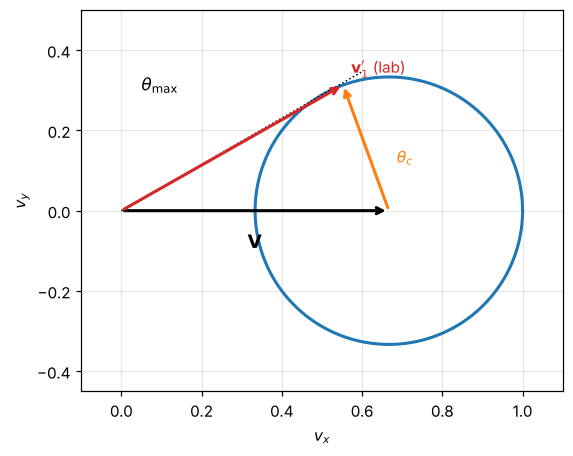

In [3]:
#| label: fig-velocity-circle
#| caption: Velocity-space picture of an elastic collision (m₁ = 2m₂, target at rest). The projectile's final lab velocity runs from the origin to a point on a circle of radius V·m₂/m₁ centered on the CM velocity V. Because the circle sits away from the origin, the lab angle can never exceed a maximum.
m1, m2, v1 = 2.0, 1.0, 1.0
V = m1 * v1 / (m1 + m2)
rad = V * m2 / m1
fig, ax = plt.subplots(figsize=(6.5, 4.5))
t = np.linspace(0, 2 * np.pi, 300)
ax.plot(V + rad * np.cos(t), rad * np.sin(t), "tab:blue", lw=2)
ax.annotate("", xy=(V, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="k", lw=2))
ax.text(V / 2, -0.05, r"$\mathbf{V}$", ha="center", va="top", fontsize=12)
tc = np.radians(110)
p = np.array([V + rad * np.cos(tc), rad * np.sin(tc)])
ax.annotate("", xy=p, xytext=(V, 0), arrowprops=dict(arrowstyle="->", color="tab:orange", lw=2))
ax.annotate("", xy=p, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="tab:red", lw=2))
ax.text(*(p + [0.02, 0.03]), r"$\mathbf{v}_1'$ (lab)", color="tab:red")
ax.text(V + 0.02, 0.12, r"$\theta_c$", color="tab:orange")
smax = np.arcsin(m2 / m1)
ax.plot([0, 1.2 * np.cos(smax) * np.sqrt(V**2 - rad**2)], [0, 1.2 * np.sin(smax) * np.sqrt(V**2 - rad**2)], "k:", lw=1)
ax.text(0.05, 0.3, r"$\theta_{\max}$", fontsize=11)
ax.set_aspect("equal"); ax.set_xlim(-0.1, 1.1); ax.set_ylim(-0.45, 0.5)
ax.set_xlabel("$v_x$"); ax.set_ylabel("$v_y$"); plt.show()

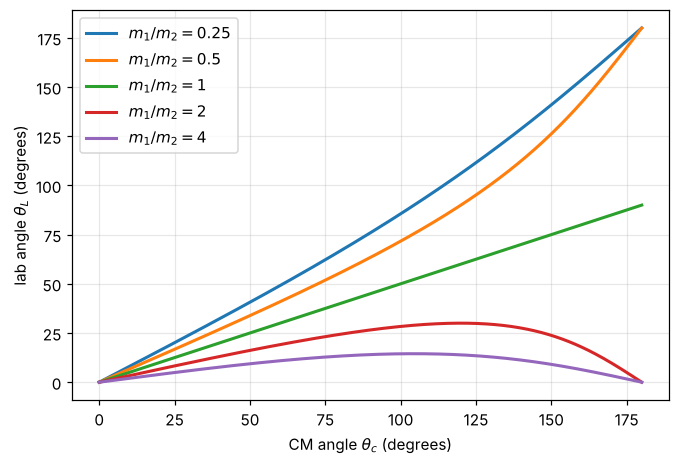

In [4]:
#| label: fig-lab-angle
#| caption: Lab scattering angle versus CM angle for several mass ratios. A light projectile (m₁/m₂ < 1) can bounce straight back; equal masses give θ_L = θ_c/2; a heavy projectile never scatters by more than arcsin(m₂/m₁).
tc = np.linspace(0, np.pi, 400)
fig, ax = plt.subplots()
for ratio in [0.25, 0.5, 1, 2, 4]:
    tl = np.arctan2(np.sin(tc), np.cos(tc) + ratio)
    ax.plot(np.degrees(tc), np.degrees(tl), lw=2, label=f"$m_1/m_2 = {ratio}$")
ax.set_xlabel(r"CM angle $\theta_c$ (degrees)"); ax.set_ylabel(r"lab angle $\theta_L$ (degrees)")
ax.legend(); plt.show()

Reading the figures:

- If $m_1 < m_2$, the circle encloses the origin and every lab angle up to $180^\circ$ is possible.
- If $m_1 = m_2$, the circle passes through the origin, $\theta_L = \theta_c/2$, and the two particles always leave at **right angles** to each other (unless the collision is head-on).
- If $m_1 > m_2$, the lab angle can never exceed $\theta_{\max}$, where $\sin\theta_{\max} = m_2/m_1$. A bowling ball cannot bounce off a ping-pong ball.

This lab/CM conversion is exactly the step that turns a CM cross section into a measured one in Goldstein's scattering chapter, the Level 3 rung of this topic.

In [5]:
# Check the right-angle rule for equal masses with sympy
tc = sp.symbols("theta_c", real=True)
V = sp.Rational(1, 2)                                   # unit-speed projectile, equal masses
v1p = sp.Matrix([V + V * sp.cos(tc), V * sp.sin(tc)])  # projectile final velocity (lab)
v2p = sp.Matrix([V - V * sp.cos(tc), -V * sp.sin(tc)]) # target final velocity (lab)
print("v1' . v2' =", sp.simplify(v1p.dot(v2p)))

v1' . v2' = 0


## Impulses as Delta Functions

During a collision the forces are huge and brief. Their details rarely matter, only their integral, the **impulse** $\mathbf{J} = \int\mathbf{F}\,dt = \Delta\mathbf{p}$. The delta function from the M2 math notes makes this exact: model the force as $\mathbf{F}(t) = \mathbf{J}\,\delta(t - t_0)$.

::::{prf:example} A kick with drag
:label: ex-kick-drag

A puck with linear drag ($m\dot v = -bv$) is at rest until it receives an impulse $J$ at $t = t_0$. Find $v(t)$.

:::{dropdown} Solution
The equation is $m\dot v + bv = J\,\delta(t - t_0)$. Before $t_0$, $v = 0$. Integrating across $t_0$, the drag term contributes nothing (it is finite over a vanishing interval), so $v$ jumps to $J/m$. After that it decays freely:

$$
v(t) = \frac Jm\,e^{-(t - t_0)/\tau}\,\Theta(t - t_0), \qquad \tau = m/b .
$$

This is the **impulse response** of the system. Because the equation is linear, the response to any force $F(t)$ is a sum of such kicks: $v(t) = \int G(t - t')F(t')\,dt'$ with $G(t) = \frac1m e^{-t/\tau}\Theta(t)$. That is the Green's-function idea, which returns in full in the oscillations notes.
:::
::::

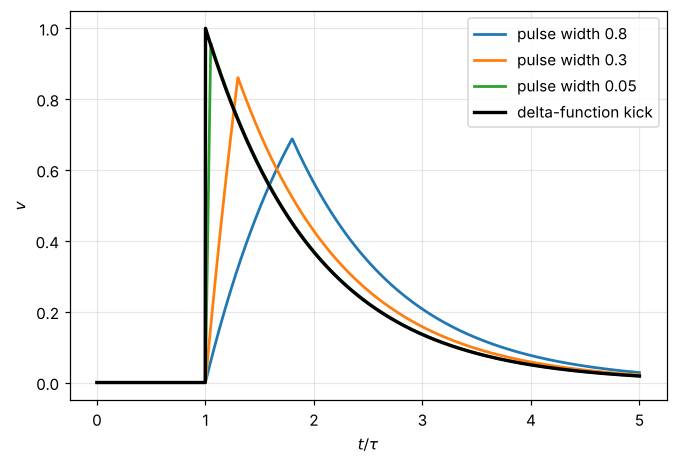

In [6]:
#| label: fig-kick
#| caption: Response of a puck with linear drag to pulses of fixed impulse J and shrinking duration. As the pulse narrows the response approaches the delta-function result (black), a jump followed by exponential decay.
m, tau, J, t0 = 1.0, 1.0, 1.0, 1.0
t = np.linspace(0, 5, 2000)
fig, ax = plt.subplots()
for w in [0.8, 0.3, 0.05]:
    F = lambda s, w=w: (J / w) * ((s > t0) & (s < t0 + w))
    sol = solve_ivp(lambda s, v: [F(s) / m - v[0] / tau], (0, 5), [0], t_eval=t, max_step=0.005)
    ax.plot(t, sol.y[0], lw=1.8, label=f"pulse width {w}")
ax.plot(t, np.where(t > t0, J / m * np.exp(-(t - t0) / tau), 0), "k", lw=2.2, label="delta-function kick")
ax.set_xlabel(r"$t/\tau$"); ax.set_ylabel("$v$"); ax.legend(); plt.show()

### Exercises

1. Two equal masses collide elastically, one initially at rest. Prove without angles that they leave at right angles.
2. Two 1 kg carts approach each other with relative speed 4 m/s and collide with $e = 0.5$. How much kinetic energy is lost?
3. A neutron (mass 1) collides elastically head-on with a carbon nucleus (mass 12) at rest. What fraction of its kinetic energy does it keep? Why are light nuclei used to slow neutrons in reactors?

:::{dropdown} Hints
1. Square the momentum equation $\mathbf{p} = \mathbf{p}_1' + \mathbf{p}_2'$ and compare with energy conservation.
2. Use $\Delta T = \tfrac12\mu v_{\text{rel}}^2(1 - e^2)$.
3. In a head-on elastic collision, $v_1' = \frac{m_1 - m_2}{m_1 + m_2}v_1$.
:::

:::{dropdown} Answers
1. $p^2 = p_1'^2 + p_2'^2 + 2\mathbf{p}_1'\cdot\mathbf{p}_2'$, while energy conservation with equal masses gives $p^2 = p_1'^2 + p_2'^2$. So $\mathbf{p}_1'\cdot\mathbf{p}_2' = 0$.
2. $\mu = 0.5$ kg, so $\Delta T = \tfrac12(0.5)(16)(0.75) = 3$ J.
3. $(11/13)^2\approx0.72$, so it loses only $28\%$ per collision. Energy transfer is largest when the masses are equal, so hydrogen- or carbon-rich moderators slow neutrons in few collisions.
:::

## Summary

- The center of mass moves as if all external forces acted on a single particle of mass $M$.
- For variable mass, write momentum balance for the whole system, exhaust included: $m\dot v = -\dot m\,u + F^{\text{ext}}$, so $\Delta v = u\ln(m_0/m)$.
- In the CM frame, an elastic collision just rotates the velocities. Only $\tfrac12\mu v_{\text{rel}}^2$ is available for inelastic losses.
- Lab and CM angles are related by {eq}`eq-lab-angle`. Heavy projectiles have a maximum scattering angle, and equal masses separate at $90^\circ$.
- Impulsive forces are delta functions, and the response to one kick (the Green's function) builds the response to any force.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.